In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')

**Experiment 0 — Data Understanding & Preparation**

In [2]:
# Membaca file CSV yang sudah ada di direktori kerja
df = pd.read_csv('UCI_Credit_Card.csv')
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [3]:
print("Jumlah baris dan kolom:", df.shape)

Jumlah baris dan kolom: (30000, 25)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   300


- Dataset memiliki 30.000 baris dan 25 kolom (`ID`, 23 variabel predictor, dan 1 target). Semua kolom bertipe numerik (int64/float64).
- Tidak ada missing value dan tidak ada data duplikat, sehingga tidak diperlukan imputasi maupun penghapusan baris.
- Target adalah `default.payment.next.month` dengan distribusi 77,88% kelas 0 (23.364) dan 22,12% kelas 1 (6.636), jadi data tidak seimbang. Karena itu F1-score dipakai sebagai metrik utama, dan split dilakukan secara stratified.

In [5]:
print(df.columns.tolist())

['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default.payment.next.month']


In [6]:
df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [7]:
print("Jumlah missing value setiap variabel:")
print(df.isnull().sum())
print("Total missing value:", df.isnull().sum().sum())

Jumlah missing value setiap variabel:
ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64
Total missing value: 0


In [8]:
print("Jumlah data duplikat:", df.duplicated().sum())

Jumlah data duplikat: 0


In [9]:
print(df['default.payment.next.month'].value_counts())
print(df['default.payment.next.month'].value_counts(normalize=True) * 100)

default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64
default.payment.next.month
0    77.88
1    22.12
Name: proportion, dtype: float64


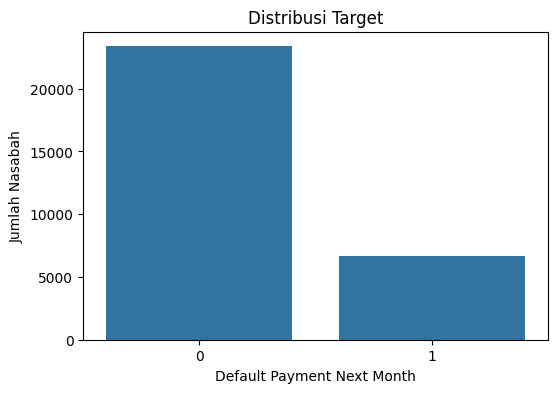

In [10]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x='default.payment.next.month'
)

plt.title('Distribusi Target')
plt.xlabel('Default Payment Next Month')
plt.ylabel('Jumlah Nasabah')
plt.show()

In [11]:
df.describe().T[['min', 'max']]
for col in df.columns:
    if df[col].nunique() <= 10:
        print(f"\n{col}:")
        print(df[col].unique())


SEX:
[2 1]

EDUCATION:
[2 1 3 5 4 6 0]

MARRIAGE:
[1 2 3 0]

PAY_5:
[-2  0 -1  2  3  5  4  7  8  6]

PAY_6:
[-2  2  0 -1  3  6  4  7  8  5]

default.payment.next.month:
[1 0]


In [12]:
print("Distribusi EDUCATION:")
print(df['EDUCATION'].value_counts().sort_index())

print("\nDistribusi MARRIAGE:")
print(df['MARRIAGE'].value_counts().sort_index())

print("\nJumlah nilai negatif pada BILL_AMT:")
print((df[[f'BILL_AMT{i}' for i in range(1, 7)]] < 0).sum())

Distribusi EDUCATION:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

Distribusi MARRIAGE:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

Jumlah nilai negatif pada BILL_AMT:
BILL_AMT1    590
BILL_AMT2    669
BILL_AMT3    655
BILL_AMT4    675
BILL_AMT5    655
BILL_AMT6    688
dtype: int64



- `EDUCATION` memiliki kode 0 (14 baris), 5 (280 baris), dan 6 (51 baris) yang tidak didefinisikan pada deskripsi dataset. Totalnya 345 baris (1,15%). `MARRIAGE` memiliki kode 0 sebanyak 54 baris (0,18%).
- `BILL_AMT1` s.d. `BILL_AMT6` memiliki nilai negatif pada 590-688 baris per bulan (sekitar 2%), yang dapat berarti kelebihan pembayaran.
- `PAY_0` s.d. `PAY_6` memuat nilai -2 dan 0 yang tidak dijelaskan eksplisit pada deskripsi dataset.


In [13]:
target = 'default.payment.next.month'

In [14]:
X = df.drop(columns=[target, 'ID'])
y = df[target]

print("Jumlah predictor:", X.shape[1])
print("Jumlah observasi:", X.shape[0])
print("Target:", target)

Jumlah predictor: 23
Jumlah observasi: 30000
Target: default.payment.next.month


In [15]:
print("Kolom predictor:")
print(X.columns.tolist())

Kolom predictor:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)
print("Ukuran y_train:", y_train.shape)
print("Ukuran y_test :", y_test.shape)

Ukuran X_train: (24000, 23)
Ukuran X_test : (6000, 23)
Ukuran y_train: (24000,)
Ukuran y_test : (6000,)


In [17]:
print("Distribusi target data training:")
print(y_train.value_counts(normalize=True))

print("\nDistribusi target data testing:")
print(y_test.value_counts(normalize=True))

Distribusi target data training:
default.payment.next.month
0    0.778792
1    0.221208
Name: proportion, dtype: float64

Distribusi target data testing:
default.payment.next.month
0    0.778833
1    0.221167
Name: proportion, dtype: float64



- Kolom `ID` dikeluarkan karena hanya identitas baris, sehingga tersisa 23 predictor.
- Data dibagi 80:20 (24.000 latih, 6.000 uji) dengan `random_state=42` dan `stratify=y`. Proporsi kelas 1 tetap sama di data latih dan data uji (sekitar 22,12%).
- Split dilakukan sebelum training dan sebelum scaling untuk mencegah data leakage. Scaling nanti dimasukkan ke dalam `Pipeline` agar dihitung hanya dari data latih (per fold saat CV).

**Experiment 1 — Baseline Model**

In [18]:
baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [19]:
y_pred_baseline = baseline_model.predict(X_test)

In [20]:
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)
baseline_precision = precision_score(y_test, y_pred_baseline)
baseline_recall = recall_score(y_test, y_pred_baseline)
baseline_f1 = f1_score(y_test, y_pred_baseline)

print("Baseline Logistic Regression")
print("--------------------------------")
print("Accuracy :", baseline_accuracy)
print("Precision:", baseline_precision)
print("Recall   :", baseline_recall)
print("F1-score :", baseline_f1)

Baseline Logistic Regression
--------------------------------
Accuracy : 0.8036666666666666
Precision: 0.6630196936542669
Recall   : 0.22833458929917105
F1-score : 0.3396860986547085


In [21]:
cv_baseline = cross_validate(
    baseline_model,
    X_train,
    y_train,
    cv=5,
    scoring={
        'accuracy': 'accuracy',
        'precision': 'precision',
        'recall': 'recall',
        'f1': 'f1'
    }
)

baseline_cv_f1 = cv_baseline['test_f1'].mean()

print("CV Accuracy :", cv_baseline['test_accuracy'].mean())
print("CV Precision:", cv_baseline['test_precision'].mean())
print("CV Recall   :", cv_baseline['test_recall'].mean())
print("CV F1-score :", baseline_cv_f1)

CV Accuracy : 0.8086249999999999
CV Precision: 0.6934998250273665
CV Recall   : 0.24411625318828306
CV F1-score : 0.36010679878766927



Baseline Logistic Regression mencapai accuracy 0,8037 tetapi F1-score hanya 0,3397 (CV F1 0,3601). Recall sangat rendah (0,2283), artinya sebagian besar nasabah yang default tidak terdeteksi. Accuracy tinggi terutama karena 77,88% data adalah kelas 0, sehingga accuracy saja tidak cukup untuk menilai model. Nilai ini menjadi pembanding untuk eksperimen berikutnya.

**Experiment 2 — Preprocessing**

In [22]:
preprocessed_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

preprocessed_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

In [23]:
y_pred_preprocessed = preprocessed_model.predict(X_test)

In [24]:
pre_accuracy = accuracy_score(y_test, y_pred_preprocessed)
pre_precision = precision_score(y_test, y_pred_preprocessed)
pre_recall = recall_score(y_test, y_pred_preprocessed)
pre_f1 = f1_score(y_test, y_pred_preprocessed)

print("Logistic Regression + Preprocessing")
print("--------------------------------------")
print("Accuracy :", pre_accuracy)
print("Precision:", pre_precision)
print("Recall   :", pre_recall)
print("F1-score :", pre_f1)

Logistic Regression + Preprocessing
--------------------------------------
Accuracy : 0.8076666666666666
Precision: 0.6868250539956804
Recall   : 0.23963828183873398
F1-score : 0.3553072625698324


In [25]:
cv_preprocessed = cross_validate(
    preprocessed_model,
    X_train,
    y_train,
    cv=5,
    scoring={
        'accuracy': 'accuracy',
        'precision': 'precision',
        'recall': 'recall',
        'f1': 'f1'
    }
)

pre_cv_f1 = cv_preprocessed['test_f1'].mean()

print("CV Accuracy :", cv_preprocessed['test_accuracy'].mean())
print("CV Precision:", cv_preprocessed['test_precision'].mean())
print("CV Recall   :", cv_preprocessed['test_recall'].mean())
print("CV F1-score :", pre_cv_f1)

CV Accuracy : 0.81125
CV Precision: 0.7130621122862941
CV Recall   : 0.24599611992381845
CV F1-score : 0.3657580584947446


In [26]:
pd.DataFrame({
    'Metric': ['CV F1-score', 'Test Accuracy', 'Test Precision', 'Test Recall', 'Test F1-score'],
    'Baseline (Exp 1)': [baseline_cv_f1, baseline_accuracy, baseline_precision, baseline_recall, baseline_f1],
    'Preprocessing (Exp 2)': [pre_cv_f1, pre_accuracy, pre_precision, pre_recall, pre_f1]
})

,Metric,Baseline (Exp 1),Preprocessing (Exp 2)
0,CV F1-score,0.360107,0.365758
1,Test Accuracy,0.803667,0.807667
2,Test Precision,0.663020,0.686825
3,Test Recall,0.228335,0.239638
4,Test F1-score,0.339686,0.355307



Preprocessing yang dipakai adalah `StandardScaler` dalam `Pipeline`. Teknik ini dipilih karena skala fitur sangat berbeda (`LIMIT_BAL` dan `BILL_AMT` dalam ratusan ribu, `PAY_x` dalam rentang -2 sampai 8), sedangkan Logistic Regression sensitif terhadap skala. Encoding tidak dilakukan karena variabel kategorik (`SEX`, `EDUCATION`, `MARRIAGE`) sudah berupa kode numerik.

Hasilnya, CV F1 naik dari 0,3601 menjadi 0,3658 dan Test F1 naik dari 0,3397 menjadi 0,3553. Accuracy, precision, dan recall juga naik. Jadi preprocessing memberi peningkatan, tetapi kecil. Recall masih rendah (0,2396).

**Experiment 3 — Model Comparison**

In [27]:
logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [28]:
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

In [29]:
random_forest_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

In [30]:
def evaluate_model(model, X_train, y_train, X_test, y_test):

    cv_results = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring={
            'accuracy': 'accuracy',
            'precision': 'precision',
            'recall': 'recall',
            'f1': 'f1'
        }
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results = {
        'CV Accuracy': cv_results['test_accuracy'].mean(),
        'CV Precision': cv_results['test_precision'].mean(),
        'CV Recall': cv_results['test_recall'].mean(),
        'CV F1': cv_results['test_f1'].mean(),
        'Test Accuracy': accuracy_score(y_test, y_pred),
        'Test Precision': precision_score(y_test, y_pred),
        'Test Recall': recall_score(y_test, y_pred),
        'Test F1': f1_score(y_test, y_pred)
    }

    return results

In [31]:
logistic_results = evaluate_model(
    logistic_model,
    X_train,
    y_train,
    X_test,
    y_test
)

decision_tree_results = evaluate_model(
    decision_tree_model,
    X_train,
    y_train,
    X_test,
    y_test
)

random_forest_results = evaluate_model(
    random_forest_model,
    X_train,
    y_train,
    X_test,
    y_test
)

In [32]:
comparison_results = pd.DataFrame(
    [
        logistic_results,
        decision_tree_results,
        random_forest_results
    ],
    index=[
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ]
)

comparison_results

,CV Accuracy,CV Precision,CV Recall,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
Logistic Regression,0.811250,0.713062,0.245996,0.365758,0.807667,0.686825,0.239638,0.355307
Decision Tree,0.727250,0.390893,0.417594,0.403747,0.714500,0.369418,0.411454,0.389305
Random Forest,0.815292,0.646594,0.363912,0.465576,0.812000,0.632490,0.357950,0.457170



Semua model dievaluasi dengan prosedur yang sama (5-fold CV pada data latih, lalu evaluasi pada data uji). Random Forest memiliki CV F1 tertinggi (0,4656) dan Test F1 tertinggi (0,4572), di atas Decision Tree (0,4037 / 0,3893) dan Logistic Regression (0,3658 / 0,3553). Random Forest dipilih untuk Experiment 4 berdasarkan hasil evaluasi tersebut.

**Experiment 4 — Hyperparameter Tuning**

In [33]:
rf_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

In [34]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

In [35]:
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(n_jobs=-1, random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             scoring='f1', verbose=1)

In [36]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV F1-score:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}

Best CV F1-score:
0.47795276241832296


In [37]:
best_rf_model = grid_search.best_estimator_

y_pred_tuned = best_rf_model.predict(X_test)

tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_precision = precision_score(y_test, y_pred_tuned)
tuned_recall = recall_score(y_test, y_pred_tuned)
tuned_f1 = f1_score(y_test, y_pred_tuned)

print("Random Forest setelah Hyperparameter Tuning")
print("---------------------------------------------")
print("Test Accuracy :", tuned_accuracy)
print("Test Precision:", tuned_precision)
print("Test Recall   :", tuned_recall)
print("Test F1-score :", tuned_f1)

Random Forest setelah Hyperparameter Tuning
---------------------------------------------
Test Accuracy : 0.8135
Test Precision: 0.6379310344827587
Test Recall   : 0.3624717407686511
Test F1-score : 0.46227775108121094


In [38]:
tuning_comparison = pd.DataFrame({
    'Metric': [
        'CV F1-score',
        'Test Accuracy',
        'Test Precision',
        'Test Recall',
        'Test F1-score'
    ],
    'Before Tuning': [
        random_forest_results['CV F1'],
        random_forest_results['Test Accuracy'],
        random_forest_results['Test Precision'],
        random_forest_results['Test Recall'],
        random_forest_results['Test F1']
    ],
    'After Tuning': [
        grid_search.best_score_,
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1
    ]
})

tuning_comparison

,Metric,Before Tuning,After Tuning
0,CV F1-score,0.465576,0.477953
1,Test Accuracy,0.812000,0.813500
2,Test Precision,0.632490,0.637931
3,Test Recall,0.357950,0.362472
4,Test F1-score,0.457170,0.462278



GridSearchCV menguji 24 kombinasi (5-fold CV, scoring F1). Kombinasi terbaik: `n_estimators=100`, `max_depth=None`, `min_samples_split=5`, `min_samples_leaf=1`. CV F1 naik dari 0,4656 ke 0,4780 dan Test F1 naik dari 0,4572 ke 0,4623. Tuning memberi peningkatan, tetapi marginal.

**Experiment 5 — Advanced Model**

In [39]:
from sklearn.model_selection import train_test_split

try:
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    print("X_train:", X_train.shape)
    print("X_test :", X_test.shape)
    print("y_train:", y_train.shape)
    print("y_test :", y_test.shape)
except NameError as e:
    print(f"Error: {e}")
    print("Silakan jalankan kembali sel pendefinisian 'X' dan 'y' di bagian atas terlebih dahulu!")

X_train: (24000, 23)
X_test : (6000, 23)
y_train: (24000,)
y_test : (6000,)


In [40]:
from sklearn.ensemble import GradientBoostingClassifier

advanced_model = GradientBoostingClassifier(
    random_state=42
)

In [41]:
from sklearn.model_selection import cross_validate

advanced_cv = cross_validate(
    advanced_model,
    X_train,
    y_train,
    cv=5,
    scoring={
        'accuracy': 'accuracy',
        'precision': 'precision',
        'recall': 'recall',
        'f1': 'f1'
    }
)

advanced_cv_f1 = advanced_cv['test_f1'].mean()

print("Gradient Boosting")
print("------------------")
print("CV Accuracy :", advanced_cv['test_accuracy'].mean())
print("CV Precision:", advanced_cv['test_precision'].mean())
print("CV Recall   :", advanced_cv['test_recall'].mean())
print("CV F1-score :", advanced_cv_f1)

Gradient Boosting
------------------
CV Accuracy : 0.8213333333333332
CV Precision: 0.6768442971238804
CV Recall   : 0.3684322255769084
CV F1-score : 0.4769937212590187


In [42]:
advanced_model.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [43]:
y_pred_advanced = advanced_model.predict(X_test)

In [44]:
advanced_accuracy = accuracy_score(y_test, y_pred_advanced)
advanced_precision = precision_score(y_test, y_pred_advanced)
advanced_recall = recall_score(y_test, y_pred_advanced)
advanced_f1 = f1_score(y_test, y_pred_advanced)

print("Gradient Boosting")
print("------------------")
print("Test Accuracy :", advanced_accuracy)
print("Test Precision:", advanced_precision)
print("Test Recall   :", advanced_recall)
print("Test F1-score :", advanced_f1)

Gradient Boosting
------------------
Test Accuracy : 0.8183333333333334
Test Precision: 0.663448275862069
Test Recall   : 0.3624717407686511
Test F1-score : 0.46881091617933723


In [45]:
advanced_comparison = pd.DataFrame({
    'Metric': [
        'CV F1-score',
        'Test Accuracy',
        'Test Precision',
        'Test Recall',
        'Test F1-score'
    ],
    'Tuned Random Forest': [
        grid_search.best_score_,
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1
    ],
    'Gradient Boosting': [
        advanced_cv_f1,
        advanced_accuracy,
        advanced_precision,
        advanced_recall,
        advanced_f1
    ]
})

advanced_comparison

,Metric,Tuned Random Forest,Gradient Boosting
0,CV F1-score,0.477953,0.476994
1,Test Accuracy,0.813500,0.818333
2,Test Precision,0.637931,0.663448
3,Test Recall,0.362472,0.362472
4,Test F1-score,0.462278,0.468811



Gradient Boosting (parameter default) memiliki CV F1 0,4770, hampir sama dengan Random Forest tuned (0,4780). Pada data uji, Gradient Boosting sedikit lebih baik: F1 0,4688 vs 0,4623, accuracy 0,8183 vs 0,8135, precision 0,6634 vs 0,6379, dengan recall yang sama (0,3625). Model advanced tidak memberi lonjakan performa, hanya keunggulan tipis. Gradient Boosting dipilih sebagai model final.